In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Titanic Dataset - Exploratory Data Analysis") 


Titanic Dataset - Exploratory Data Analysis


In [31]:
df = pd.read_csv("train.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [32]:
# Dataset ki information
print("Dataset Information:")
df.info()

print("\nMissing Values in Each Column:")
print(df.isnull().sum())

print("\nStatistical Summary:")
df.describe()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Missing Values in Each Column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          6

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Survived
0    549
1    342
Name: count, dtype: int64


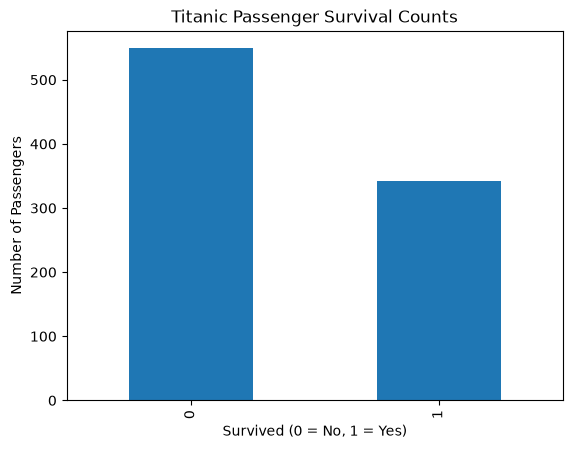

In [33]:
# Count of passengers who survived and did not survive
print(df["Survived"].value_counts())

df["Survived"].value_counts().plot(
    kind="bar",
    title="Titanic Passenger Survival Counts",
    xlabel="Survived (0 = No, 1 = Yes)",
    ylabel="Number of Passengers"
)

plt.show()

Survival Percentage by Gender:
Survived      0      1
Sex                   
female    25.80  74.20
male      81.11  18.89


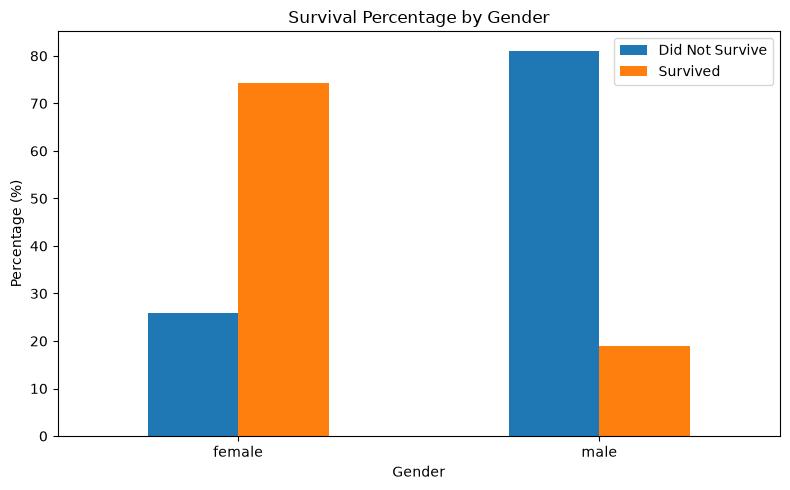

In [34]:
# Survival rate by gender
gender_survival = pd.crosstab(
    df["Sex"],
    df["Survived"],
    normalize="index"
) * 100

print("Survival Percentage by Gender:")
print(gender_survival.round(2))

gender_survival.plot(
    kind="bar",
    figsize=(8, 5),
    title="Survival Percentage by Gender",
    xlabel="Gender",
    ylabel="Percentage (%)"
)

plt.legend(["Did Not Survive", "Survived"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Survival Percentage by Passenger Class:
Survived      0      1
Pclass                
1         37.04  62.96
2         52.72  47.28
3         75.76  24.24


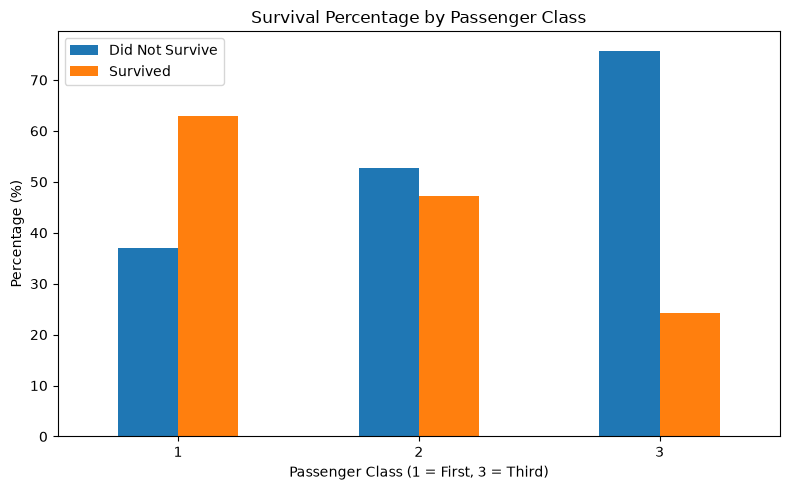

In [35]:
# Survival rate by passenger class
class_survival = pd.crosstab(
    df["Pclass"],
    df["Survived"],
    normalize="index"
) * 100

print("Survival Percentage by Passenger Class:")
print(class_survival.round(2))

class_survival.plot(
    kind="bar",
    figsize=(8, 5),
    title="Survival Percentage by Passenger Class",
    xlabel="Passenger Class (1 = First, 3 = Third)",
    ylabel="Percentage (%)"
)

plt.legend(["Did Not Survive", "Survived"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("class_survival.png", dpi=300, bbox_inches="tight")
plt.show()

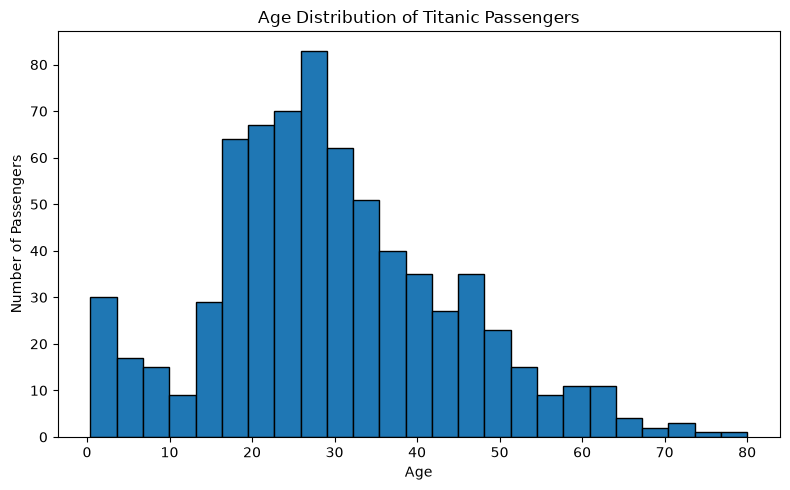

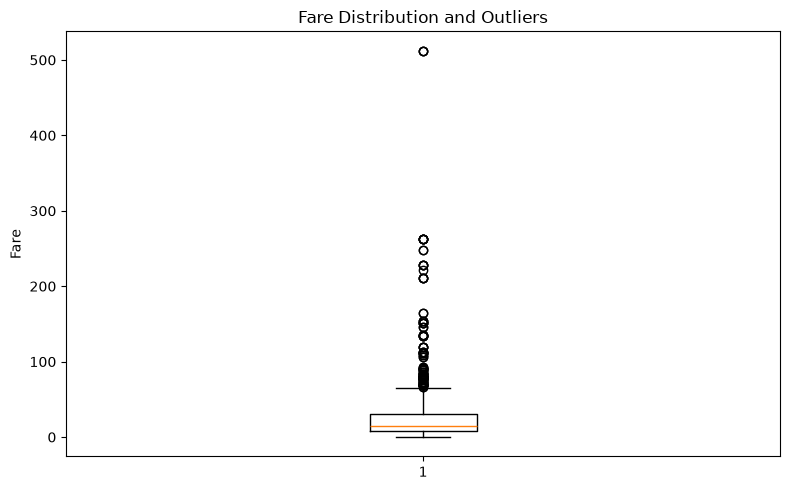

In [36]:
# Age distribution
plt.figure(figsize=(8, 5))
plt.hist(df["Age"].dropna(), bins=25, edgecolor="black")
plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.tight_layout()
plt.show()

# Fare distribution
plt.figure(figsize=(8, 5))
plt.boxplot(df["Fare"].dropna())
plt.title("Fare Distribution and Outliers")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()

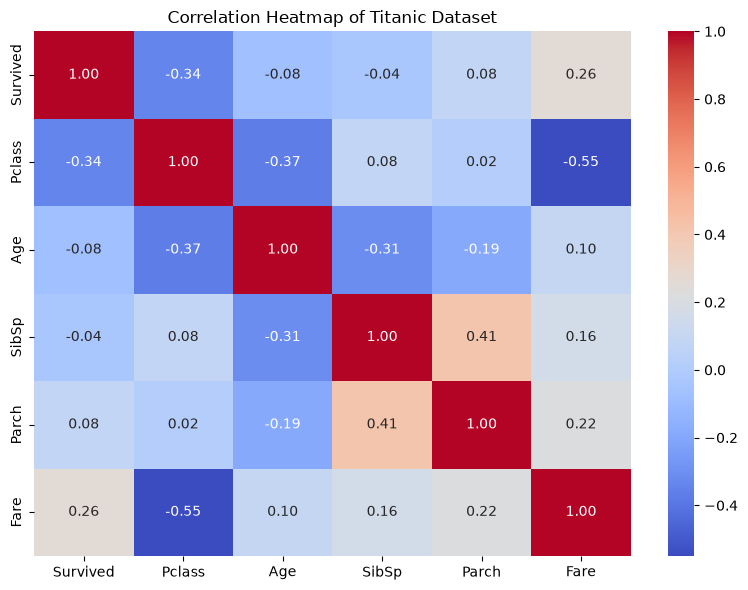

In [37]:
# Correlation heatmap
numeric_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]

correlation = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Titanic Dataset")
plt.tight_layout()
plt.show()

In [38]:
from scipy.stats import chi2_contingency

# Test whether gender and survival are associated
contingency_table = pd.crosstab(df["Sex"], df["Survived"])
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-square statistic:", round(chi2, 3))
print("P-value:", round(p_value, 6))

if p_value < 0.05:
    print("Result: Gender and survival are statistically associated.")
else:
    print("Result: No statistically significant association was found.")

Chi-square statistic: 260.717
P-value: 0.0
Result: Gender and survival are statistically associated.


# Key Findings

1. The Titanic training dataset contains 891 passengers and 12 columns.
2. Some values are missing, especially in the Age and Cabin columns.
3. Survival differed between male and female passengers.
4. Survival rates also varied across passenger classes.
5. The age histogram shows the distribution of passenger ages.
6. The fare box plot helps identify variation and possible outliers.
7. The correlation heatmap summarizes relationships among numerical variables.

# Conclusion

Exploratory Data Analysis helped identify missing values, understand passenger characteristics, and explore patterns associated with survival. These findings can guide further data cleaning and predictive modelling.